<a href="https://colab.research.google.com/github/minhphu12-oc/gg-colab/blob/sklearn-project-for-machine-learning/project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PROJECT 1

link data : https://drive.google.com/drive/folders/1hxRpXFqDR6PypjdXSIe0DvhqE3TVwK7k

upload dataset đề bài đã đưa lên

In [60]:
from google.colab import files
uploaded = files.upload()

Saving Social_Network_Ads.csv to Social_Network_Ads (4).csv


In [61]:
import pandas as pd
file_path = "Social_Network_Ads.csv"
data = pd.read_csv(file_path)

bắt đầu phân tích dữ liệu

In [62]:
# nhìn sơ qua các cột để tìm target
print(data.head(5).to_string())
print(data.tail(5).to_string())

    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0
      User ID  Gender  Age  EstimatedSalary  Purchased
395  15691863  Female   46            41000          1
396  15706071    Male   51            23000          1
397  15654296  Female   50            20000          1
398  15755018    Male   36            33000          0
399  15594041  Female   49            36000          1


In [63]:
# đọc thông tin dữ liệu từ mean,std,max min, ...
print(data.describe())

            User ID         Age  EstimatedSalary   Purchased
count  4.000000e+02  400.000000       400.000000  400.000000
mean   1.569154e+07   37.655000     69742.500000    0.357500
std    7.165832e+04   10.482877     34096.960282    0.479864
min    1.556669e+07   18.000000     15000.000000    0.000000
25%    1.562676e+07   29.750000     43000.000000    0.000000
50%    1.569434e+07   37.000000     70000.000000    0.000000
75%    1.575036e+07   46.000000     88000.000000    1.000000
max    1.581524e+07   60.000000    150000.000000    1.000000


qua bảng trên ta có thể thấy được: dataset có 400 đối tượng được nghiên cứu , Age nghiên cứu chủ yếu là từ 27-47 tuổi với 37 tuổi là trung bình, min là 18 tuổi và max là 60 tuổi, tỉ lệ người mua xe khá ít khi chỉ 35,75% quyết định là có mua xe

tiếp theo ta phải kiểm tra xem có dữ liệu nào còn thiếu không để đưa ra hướng thế dữ liệu thiếu.


In [64]:
print(data.isnull().sum())
print(data.isnull().sum().sum())

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64
0


như vậy là không có dữ kiện thiếu

In [65]:
#ta xem thử từng thuộc tính của data
print(data.dtypes)

User ID             int64
Gender             object
Age                 int64
EstimatedSalary     int64
Purchased           int64
dtype: object


thấy hầu hết sẽ là dạng int64 ( số nguyên ) và có Gender là object nên ta sẽ phải biến đổi nó về dạng số để thuận tiện cho máy học.

Sử dụng thư viện scikit-learn để training model

In [66]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
# tách data 80/20 theo đề bài
x = data.drop("Purchased", axis = 1)
y = data["Purchased"]
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state = 42)

Bắt đầu xây dựng và thử từng model

In [67]:
# LogisticRegression
pipeline = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore")),("model", LogisticRegression())])
pipeline.fit(x_train, y_train)
prediction = pipeline.predict(x_test)
print("LogisticRegression")
print(f"Accuracy: {accuracy_score(y_test, prediction)*100}%")
print(f"F1: {f1_score(y_test, prediction)*100:.2f}%")
print(f"Precision: {precision_score(y_test, prediction)*100:.2f}%")
print(f"Recall: {recall_score(y_test, prediction)*100:.2f}%")

LogisticRegression
Accuracy: 82.0%
F1: 68.97%
Precision: 95.24%
Recall: 54.05%


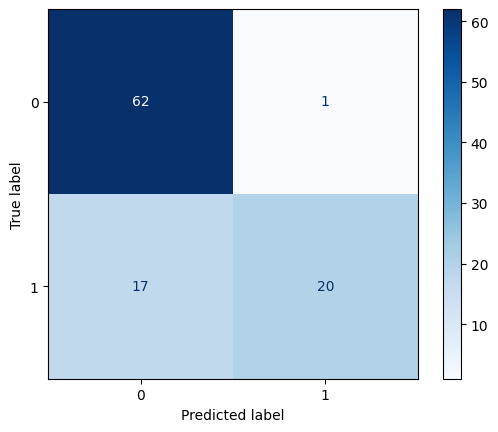

In [68]:
labels = [0, 1]
cm = confusion_matrix(y_test, prediction)
dis = ConfusionMatrixDisplay(cm, display_labels=labels)
dis.plot(cmap = "Blues")
plt.show()

Tiếp theo chúng ta thử thay đổi các parameters xem nó có tăng được độ chính xác, recall, ... lên không ?

In [69]:
param_grid = {"model__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}
grid_search = GridSearchCV(pipeline, param_grid, cv = 5, scoring = "accuracy")
grid_search.fit(x_train, y_train)
prediction = grid_search.predict(x_test)
print("LogisticRegression")
print(f"Accuracy: {accuracy_score(y_test, prediction)*100}%")
print(f"F1: {f1_score(y_test, prediction)*100:.2f}%")
print(f"Precision: {precision_score(y_test, prediction)*100:.2f}%")
print(f"Recall: {recall_score(y_test, prediction)*100:.2f}%")
print(f"Best parameters : {grid_search.best_params_} | Best score : {grid_search.best_score_ * 100 :.2f}")

LogisticRegression
Accuracy: 83.0%
F1: 74.63%
Precision: 83.33%
Recall: 67.57%
Best parameters : {'model__C': 1000} | Best score : 78.67


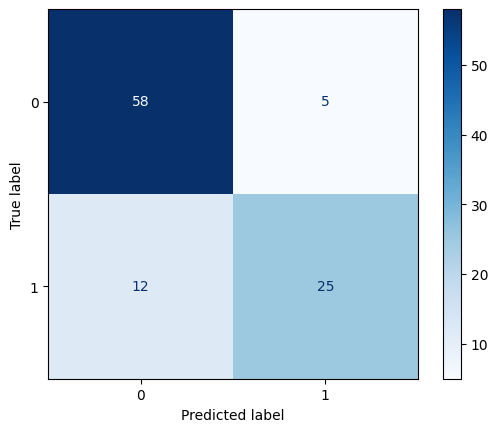

In [70]:
labels = [0, 1]
cm = confusion_matrix(y_test, prediction)
dis = ConfusionMatrixDisplay(cm, display_labels=labels)
dis.plot(cmap = "Blues")
plt.show()

như vậy chúng ta thấy máy đã cải thiện rất nhiều khi thay đổi C lên 1000 . ta có thể thấy precision giảm đi nhưng recall lại tăng lên đáng kể . như vậy máy đã dự đoán kém đi nhưng lại có thể gọi chính xác được cao hơn .

giờ ta sẽ thử model decision tree

In [71]:
pipeline = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore")),("model", DecisionTreeClassifier())])
pipeline.fit(x_train, y_train)
prediction = pipeline.predict(x_test)
print("DecisionTreeClassifier")
print(f"Accuracy: {accuracy_score(y_test, prediction)*100}%")
print(f"F1: {f1_score(y_test, prediction)*100:.2f}%")
print(f"Precision: {precision_score(y_test, prediction)*100:.2f}%")
print(f"Recall: {recall_score(y_test, prediction)*100:.2f}%")

DecisionTreeClassifier
Accuracy: 77.0%
F1: 62.30%
Precision: 79.17%
Recall: 51.35%


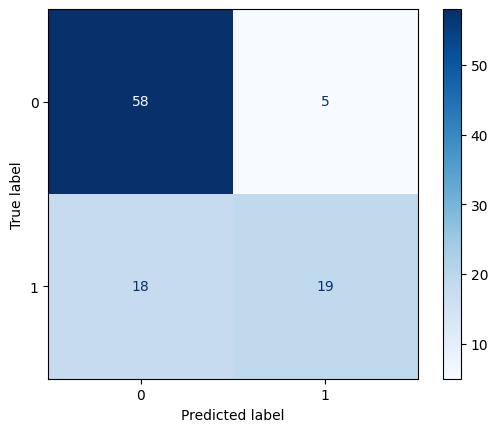

In [72]:
labels = [0, 1]
cm = confusion_matrix(y_test, prediction)
dis = ConfusionMatrixDisplay(cm, display_labels=labels)
dis.plot(cmap = "Blues")
plt.show()

có vẻ model này ban đầu có tỉ lệ dự đoán kém hơn model logisticregression khá nhiều .vậy thì ta thử tuning nó xem liệu nó có ưu điểm gì hơn model logistic không ?

In [73]:
param_grid = {"model__max_depth": [3, 5, 7, 10, None],
              "model__min_samples_split": [2, 5, 10],
              "model__min_samples_leaf": [1, 2, 4],
              "model__criterion": ["gini", "entropy"]}
grid = GridSearchCV(pipeline, param_grid, cv = 5, scoring = "accuracy")
grid.fit(x_train, y_train)
prediction = grid.predict(x_test)
print("DecisionTreeClassifier")
print(f"Accuracy: {accuracy_score(y_test, prediction)*100:.2f}%")
print(f"F1: {f1_score(y_test, prediction)*100:.2f}%")
print(f"Precision: {precision_score(y_test, prediction)*100:.2f}%")
print(f"Recall: {recall_score(y_test, prediction)*100:.2f}%")
print(f"Best parameters : {grid.best_params_} | Best score : {grid.best_score_ * 100 :.2f}")

DecisionTreeClassifier
Accuracy: 73.00%
F1: 54.24%
Precision: 72.73%
Recall: 43.24%
Best parameters : {'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5} | Best score : 79.67


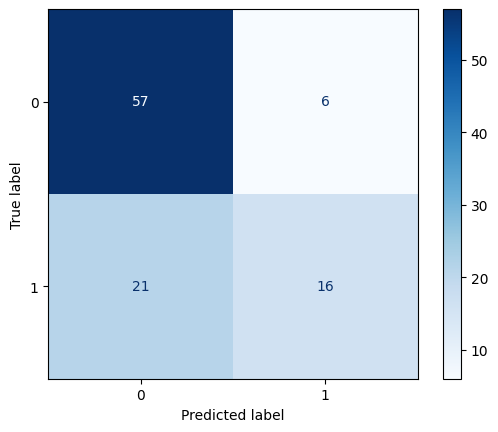

In [74]:
labels = [0, 1]
cm = confusion_matrix(y_test, prediction)
dis = ConfusionMatrixDisplay(cm, display_labels=labels)
dis.plot(cmap = "Blues")
plt.show()

như ta thấy , tuy có thay đổi và cải thiện hơn nhưng khi so với model ban đầu thì thực sự là tỉ lệ dự đoán đúng cách quá xa.

vậy thì giờ ta sẽ thử đến với một phiên bản nâng cấp hơn của decisiontree, thay vì chỉ đợi 1 cây phân biệt thì ta sẽ chia thành nhiều cây với nhiều feature khác nhau .

Model : Randomforest

In [75]:
pipeline = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore")),("model", RandomForestClassifier())])
pipeline.fit(x_train, y_train)
prediction = pipeline.predict(x_test)
print("RandomForestClassifier")
print(f"Accuracy: {accuracy_score(y_test, prediction)*100:.2f}%")
print(f"F1: {f1_score(y_test, prediction)*100:.2f}%")
print(f"Precision: {precision_score(y_test, prediction)*100:.2f}%")
print(f"Recall: {recall_score(y_test, prediction)*100:.2f}%")

RandomForestClassifier
Accuracy: 77.00%
F1: 54.90%
Precision: 100.00%
Recall: 37.84%


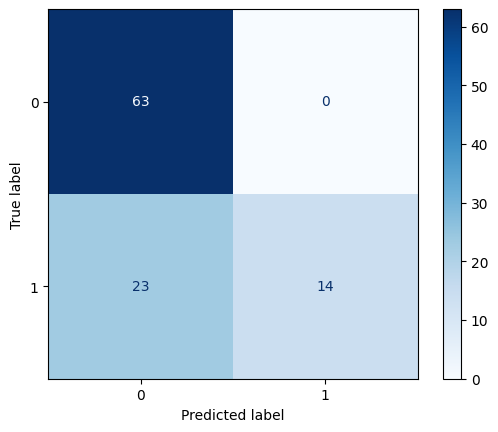

In [76]:
labels = [0, 1]
cm = confusion_matrix(y_test, prediction)
dis = ConfusionMatrixDisplay(cm, display_labels=labels)
dis.plot(cmap = "Blues")
plt.show()

nếu không điều chỉnh gì thì tỉ lệ dự đoán nhìn có vẻ như là tệ nhất trong 2 model ta vừa thử. nhưng giờ hãy thử tuning nó


In [77]:
kf = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
param_grid = {"model__n_estimators": [50, 100, 200],
              "model__max_depth" : [5, 10, 20, None],
              "model__min_samples_split" : [2, 5, 10],
              "model__min_samples_leaf": [1, 2, 4] }
grid = GridSearchCV(pipeline, param_grid, cv = kf, scoring = "accuracy")
grid.fit(x_train, y_train)
prediction = grid.predict(x_test)
print("RandomForestClassifier")
print(f"Accuracy: {accuracy_score(y_test, prediction)*100:.2f}%")
print(f"F1: {f1_score(y_test, prediction)*100:.2f}%")
print(f"Precision: {precision_score(y_test, prediction)*100:.2f}%")
print(f"Recall: {recall_score(y_test, prediction)*100:.2f}%")
print(f"Best parameters : {grid.best_params_} | Best score : {grid.best_score_ * 100 :.2f}")

RandomForestClassifier
Accuracy: 73.00%
F1: 42.55%
Precision: 100.00%
Recall: 27.03%
Best parameters : {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__n_estimators': 50} | Best score : 75.33


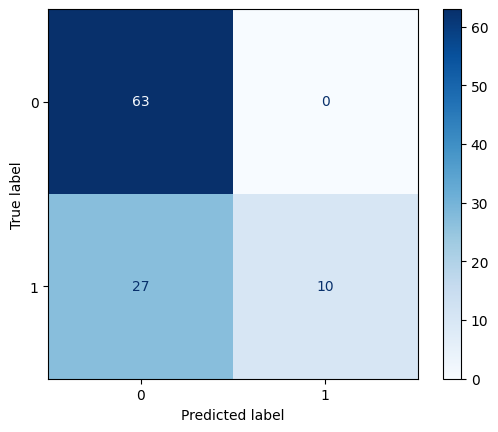

In [78]:
labels = [0, 1]
cm = confusion_matrix(y_test, prediction)
dis = ConfusionMatrixDisplay(cm, display_labels=labels)
dis.plot(cmap = "Blues")
plt.show()

precision 100% nhưng thực tế model chỉ chỉ đúng 43,24% thôi . tỉ lệ có vẻ cải thiện hơn nhưng vẫn để lại khoảng cách khá xa so với logistic .

Vậy giờ ta thử chuyển qua một model khác hẳn với các model cây này , MODEL KNN

do KNN phụ thuộc rất mạnh vào khoảng cách , số tuổi và số lương cách nhau một khoảng rất lớn nên model có thể sẽ bị kéo mạnh về phía lương dự đoán dẫn đến sai lệch. vì vậy chúng ta phải scaler , thu hẹp khoảng cách của các số lại với nhau để tránh model học sai.

In [79]:
# chuẩn hoá số và phân loại
numerical = ["User ID", "Age", "EstimatedSalary"]
categorical = ["Gender"]
preprocessor = ColumnTransformer([("numerical", StandardScaler(), numerical),
                                   ("categorical",OneHotEncoder(handle_unknown="ignore"), categorical)])
pipeline = Pipeline([("preprocessor", preprocessor),("model", KNeighborsClassifier())])
pipeline.fit(x_train, y_train)
prediction = pipeline.predict(x_test)
print("KNeighborsClassifier")
print(f"Accuracy: {accuracy_score(y_test, prediction)*100:.2f}%")
print(f"F1: {f1_score(y_test, prediction)*100:.2f}%")
print(f"Precision: {precision_score(y_test, prediction)*100:.2f}%")
print(f"Recall: {recall_score(y_test, prediction)*100:.2f}%")

KNeighborsClassifier
Accuracy: 93.00%
F1: 90.41%
Precision: 91.67%
Recall: 89.19%


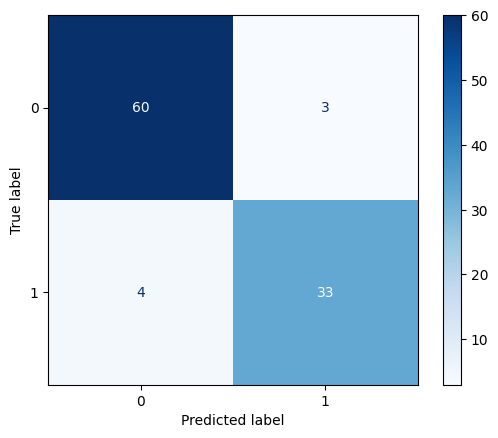

In [80]:
labels = [0, 1]
cm = confusion_matrix(y_test, prediction)
dis = ConfusionMatrixDisplay(cm, display_labels=labels)
dis.plot(cmap = "Blues")
plt.show()

thực sự KNN đã đưa ra kết quả tốt nhất ngay từ ban đầu mà chưa chỉnh sửa gì với tỉ lệ chính xác lên đến tận 93% . vậy liệu model này còn có thể tăng được tỉ lệ chính xác nữa không ?

In [81]:
param_grid = {"model__n_neighbors" : [1, 3, 5, 7, 9, 11],
              "model__weights" : ["uniform", "distance"]}
kf = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
grid = GridSearchCV(pipeline, param_grid, cv = kf, scoring = "accuracy")
grid.fit(x_train, y_train)
prediction = grid.predict(x_test)
print("KNeighborsClassifier")
print(f"Accuracy: {accuracy_score(y_test, prediction)*100:.2f}%")
print(f"F1: {f1_score(y_test, prediction)*100:.2f}%")
print(f"Precision: {precision_score(y_test, prediction)*100:.2f}%")
print(f"Recall: {recall_score(y_test, prediction)*100:.2f}%")
print(f"Best parameters : {grid.best_params_} | Best score : {grid.best_score_ * 100 : .2f}")

KNeighborsClassifier
Accuracy: 94.00%
F1: 91.67%
Precision: 94.29%
Recall: 89.19%
Best parameters : {'model__n_neighbors': 7, 'model__weights': 'uniform'} | Best score :  87.67


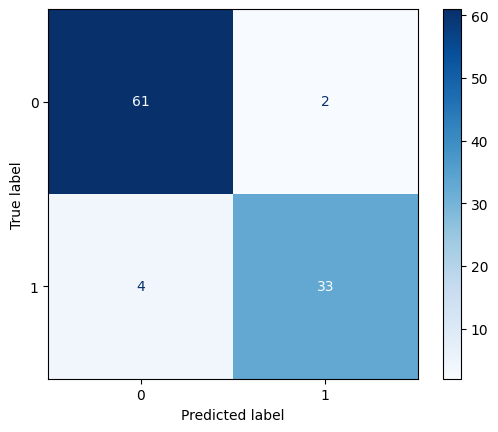

In [82]:
labels = [0, 1]
cm = confusion_matrix(y_test, prediction)
dis = ConfusionMatrixDisplay(cm, display_labels=labels)
dis.plot(cmap = "Blues")
plt.show()

model đã cải thiện hơn được một chút khi ta tuning .

# kết luận

như vậy sau 4 model ta kết luận được:
- logisticregression và knn là hai model có thể dự đoán tốt nhất khả năng mua xe của khách hàng với knn là model dự đoán tốt nhất với 94% khả năng dự đoán chính xác.
- hai model cây còn lại thì dự đoán chính xác rất thấp và gần như bị bỏ lại với khoảng cách khá xa so với model còn lại, kể cả khi đã tuning để cải thiện tỉ lệ dự đoán.

=>> như vậy, chúng ta sẽ ưu tiên sử dụng model KNN trong bài toán này để phân loại khách có mua hay không ?

thêm model neural MLP

In [89]:
import torch
import torch.nn as nn
import torch.optim as optim

# chuyển dữ liệu về dạng tensor để dựng model
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

x_train_t = torch.FloatTensor(x_train_processed)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)
x_test_t = torch.FloatTensor(x_test_processed)
y_test_t = torch.tensor(y_test.values, dtype=torch.long)

# dựng model
class MLP(nn.Module):
  def __init__(self, input_dim, hidden1, hidden2, output_dim):
    super().__init__()
    self.linear1 = nn.Linear(input_dim, hidden1)
    self.relu1 = nn.ReLU()
    self.linear2 = nn.Linear(hidden1, hidden2)
    self.relu2 = nn.ReLU()
    self.linear3 = nn.Linear(hidden2, output_dim)

  def forward(self, x):
    out = self.linear1(x)
    out = self.relu1(out)
    out = self.linear2(out)
    out = self.relu2(out)
    out = self.linear3(out)
    return out

model = MLP(input_dim = x_train_t.shape[1], hidden1 = 64, hidden2 = 32, output_dim = 2)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr = 0.001)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
x_train_t = x_train_t.to(device)
y_train_t = y_train_t.to(device)
x_test_t = x_test_t.to(device)
y_test_t = y_test_t.to(device)
for epoch in range(200):
  optimizer.zero_grad()
  model.train()
  loss = loss_fn(model(x_train_t), y_train_t)
  loss.backward()
  optimizer.step()
  if epoch % 100 == 0:
    model.eval()
    with torch.no_grad():
      prediction = model(x_test_t)
      print("========================================================")
      print(f"Epoch : {epoch}")
      print(f"Accuracy: {accuracy_score(y_test_t.cpu().numpy(), prediction.argmax(dim = 1).cpu().numpy())*100:.2f}%")
      print(f"F1: {f1_score(y_test_t.cpu().numpy(), prediction.argmax(dim = 1).cpu().numpy())*100:.2f}%")
      print(f"Precision: {precision_score(y_test_t.cpu().numpy(), prediction.argmax(dim = 1).cpu().numpy())*100:.2f}%")
      print(f"Recall: {recall_score(y_test_t.cpu().numpy(), prediction.argmax(dim = 1).cpu().numpy())*100:.2f}%")
      print("=========================================================")
      print()

Epoch : 0
Accuracy: 65.00%
F1: 10.26%
Precision: 100.00%
Recall: 5.41%

Epoch : 100
Accuracy: 93.00%
F1: 90.91%
Precision: 87.50%
Recall: 94.59%



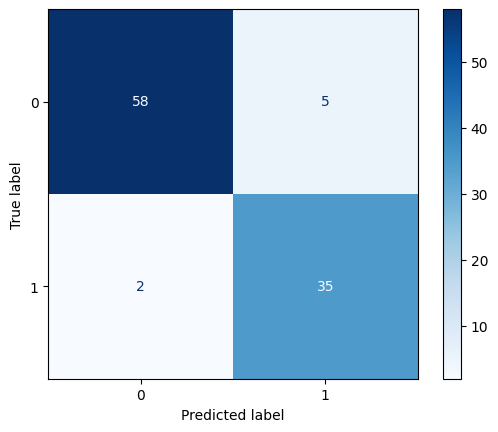

In [90]:
labels = [0, 1]

y_true_np = y_test_t.cpu().numpy()
y_pred_np = prediction.argmax(dim=1).cpu().numpy()

cm = confusion_matrix(y_true_np, y_pred_np)
dis = ConfusionMatrixDisplay(cm, display_labels=labels)
dis.plot(cmap = "Blues")
plt.show()

Ta thấy với model neural nhiều lớp MLP , đã cải thiện thêm được chỉ số F1 của model vượt xa hơn cả model KNN mà chúng ta đã làm được trước đó. Tại mốc bước nhảy 100 và chỉ số giảm dần tại các bước nhảy sau đó.